# Machine Learning for Next-Day Rain Prediction in Lund

> Author：Haoyang Qian, Ruowen Xiao
>
> Date: 2026/10/18

**Before this, first run `get_data.ipynb` to fetch training data named `./data/lund_daily_weather.csv`.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    silhouette_score
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

## 1. Data Processing and Exploration

### Data Loading & Exploration

In [ ]:
sns.set_theme(style="whitegrid")
df_daily = pd.read_csv("./data/lund_daily_weather.csv")

print("Dataset Shape:", df_daily.shape)
print("\n--- First 5 rows ---")
display(df_daily.head())

print("\n--- Data Types and Missing Values ---")
df_daily.info()

Dataset Shape: (5478, 16)

--- First 5 rows ---


,date,temp_max,temp_min,temp_mean,humidity_mean,dewpoint_mean,pressure_mean,cloud_cover_mean,wind_speed_max,precipitation_today,temp_range,dewpoint_spread,pressure_change,month_sin,month_cos,rain_tomorrow
0,2010-01-01,-4.7,-8.3,-6.741667,80.208333,-9.629167,996.700000,83.125000,14.1,0.0,3.6,2.887500,0.000000,0.5,0.866025,0
1,2010-01-02,-4.0,-9.5,-6.683333,78.291667,-9.900000,1007.425000,22.875000,19.4,0.0,5.5,3.216667,10.725000,0.5,0.866025,0
2,2010-01-03,-5.9,-11.5,-9.350000,75.791667,-12.862500,1013.662500,33.250000,11.3,0.0,5.6,3.512500,6.237500,0.5,0.866025,1
3,2010-01-04,-1.0,-6.1,-3.137500,86.541667,-5.079167,1004.058333,85.000000,24.3,1.4,5.1,1.941667,-9.604167,0.5,0.866025,1
4,2010-01-05,-0.7,-2.6,-1.825000,93.166667,-2.779167,999.670833,89.583333,13.4,1.5,1.9,0.954167,-4.387500,0.5,0.866025,1



--- Data Types and Missing Values ---
<class 'pandas.DataFrame'>
RangeIndex: 5478 entries, 0 to 5477
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 5478 non-null   str    
 1   temp_max             5478 non-null   float64
 2   temp_min             5478 non-null   float64
 3   temp_mean            5478 non-null   float64
 4   humidity_mean        5478 non-null   float64
 5   dewpoint_mean        5478 non-null   float64
 6   pressure_mean        5478 non-null   float64
 7   cloud_cover_mean     5478 non-null   float64
 8   wind_speed_max       5478 non-null   float64
 9   precipitation_today  5478 non-null   float64
 10  temp_range           5478 non-null   float64
 11  dewpoint_spread      5478 non-null   float64
 12  pressure_change      5478 non-null   float64
 13  month_sin            5478 non-null   float64
 14  month_cos            5478 non-null   float64
 15  rain_tomor

In [3]:
print("Dataset shape:", df_daily.shape)
print("Date range:",
      df_daily["date"].min(),
      "to",
      df_daily["date"].max())

print("Duplicate dates:", df_daily["date"].duplicated().sum())

dates = pd.to_datetime(df_daily["date"]).sort_values()
date_gaps = (dates.diff().dropna().dt.days > 1).sum()
print("Date gaps:", date_gaps)

print("\nMissing values:")
print(df_daily.isna().sum())

print("\nRainTomorrow counts:")
print(df_daily["rain_tomorrow"].value_counts(dropna=False))

print("\nRainTomorrow proportions:")
print(df_daily["rain_tomorrow"].value_counts(normalize=True))

Dataset shape: (5478, 16)
Date range: 2010-01-01 to 2024-12-30
Duplicate dates: 0
Date gaps: 0

Missing values:
date                   0
temp_max               0
temp_min               0
temp_mean              0
humidity_mean          0
dewpoint_mean          0
pressure_mean          0
cloud_cover_mean       0
wind_speed_max         0
precipitation_today    0
temp_range             0
dewpoint_spread        0
pressure_change        0
month_sin              0
month_cos              0
rain_tomorrow          0
dtype: int64

RainTomorrow counts:
rain_tomorrow
1    3049
0    2429
Name: count, dtype: int64

RainTomorrow proportions:
rain_tomorrow
1    0.55659
0    0.44341
Name: proportion, dtype: float64


### Descriptive Statistics

In [4]:
numeric_features = df_daily.select_dtypes(include="number").drop(
    columns=["rain_tomorrow"]
)

# Descriptive statistics
print("Descriptive Statistics:")
print(numeric_features.describe().T.round(2))

Descriptive Statistics:
                      count     mean    std     min      25%      50%  \
temp_max             5478.0    11.96   7.52  -10.00     6.10    11.80   
temp_min             5478.0     5.98   6.55  -18.00     1.30     6.10   
temp_mean            5478.0     8.99   6.90  -13.92     3.87     8.89   
humidity_mean        5478.0    80.37   9.73   45.42    73.38    81.25   
dewpoint_mean        5478.0     5.51   6.32  -17.28     1.26     5.58   
pressure_mean        5478.0  1007.17  10.01  966.18  1001.17  1007.73   
cloud_cover_mean     5478.0    67.35  26.83    0.00    49.47    72.92   
wind_speed_max       5478.0    22.30   7.92    5.20    16.60    21.40   
precipitation_today  5478.0     2.01   3.64    0.00     0.00     0.30   
temp_range           5478.0     5.98   2.95    0.50     3.70     5.50   
dewpoint_spread      5478.0     3.48   2.01    0.07     1.85     3.16   
pressure_change      5478.0     0.00   6.12  -28.94    -3.57    -0.12   
month_sin            5478.0

### Data Visualization

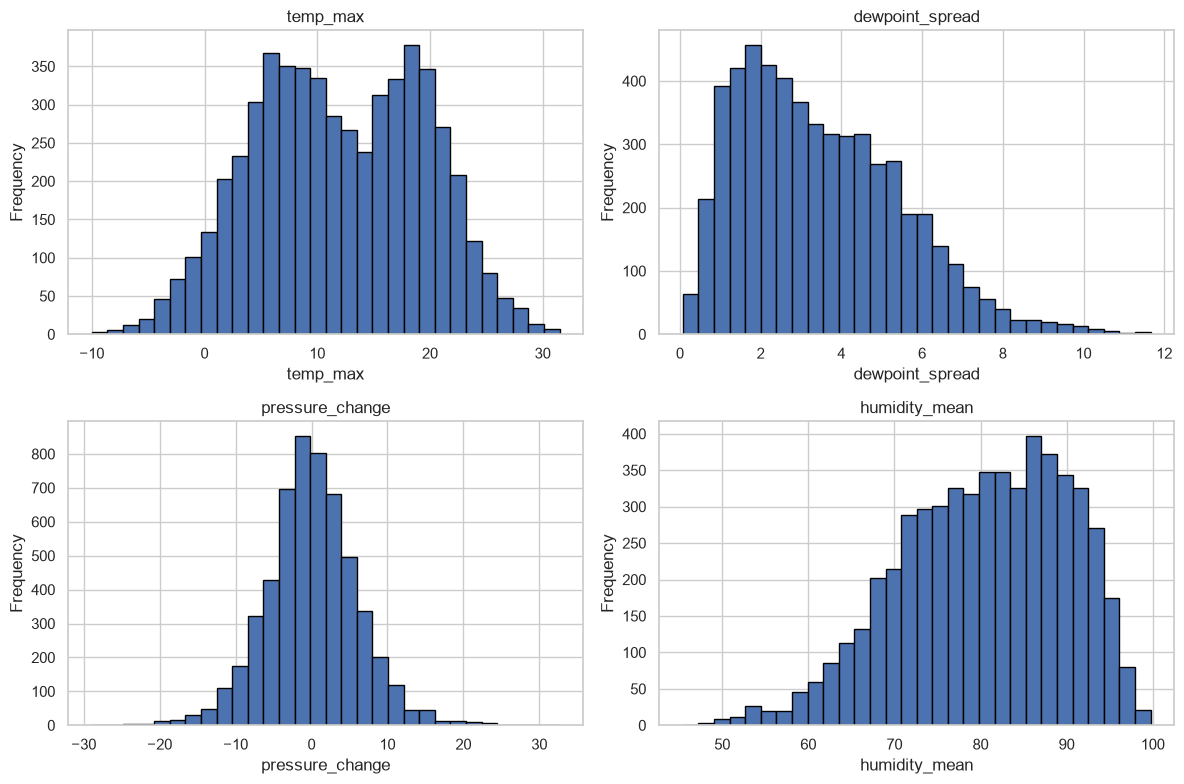

In [5]:
features_to_plot = [
    "temp_max",
    "dewpoint_spread",
    "pressure_change",
    "humidity_mean"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, features_to_plot):
    ax.hist(df_daily[feature], bins=30, edgecolor="black")
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [6]:
# 1. Check distribution skewness
features_to_check = [
    "temp_max",
    "dewpoint_spread",
    "pressure_change",
    "humidity_mean",
    "precipitation_today",
    "wind_speed_max"
]

print("=== Distribution Skewness ===")
print(df_daily[features_to_check].skew().round(2))


# 2. Detect potential outliers using the IQR rule
print("\n=== Potential Outliers (IQR Rule) ===")

for col in features_to_check:
    q1 = df_daily[col].quantile(0.25)
    q3 = df_daily[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df_daily[
        (df_daily[col] < lower) |
        (df_daily[col] > upper)
    ]

    print(
        f"{col}: {len(outliers)} potential outliers "
        f"({len(outliers) / len(df_daily) * 100:.2f}%)"
    )


# 3. Explore the relationship between pressure and humidity
print("\n=== Pressure-Humidity Correlation ===")

print(
    "Pearson correlation:",
    round(df_daily["pressure_mean"].corr(
        df_daily["humidity_mean"], method="pearson"
    ), 3)
)

print(
    "Spearman correlation:",
    round(df_daily["pressure_mean"].corr(
        df_daily["humidity_mean"], method="spearman"
    ), 3)
)

=== Distribution Skewness ===
temp_max              -0.04
dewpoint_spread        0.71
pressure_change        0.06
humidity_mean         -0.43
precipitation_today    3.56
wind_speed_max         0.69
dtype: float64

=== Potential Outliers (IQR Rule) ===
temp_max: 0 potential outliers (0.00%)
dewpoint_spread: 49 potential outliers (0.89%)
pressure_change: 161 potential outliers (2.94%)
humidity_mean: 15 potential outliers (0.27%)
precipitation_today: 550 potential outliers (10.04%)
wind_speed_max: 80 potential outliers (1.46%)

=== Pressure-Humidity Correlation ===
Pearson correlation: -0.229
Spearman correlation: -0.218


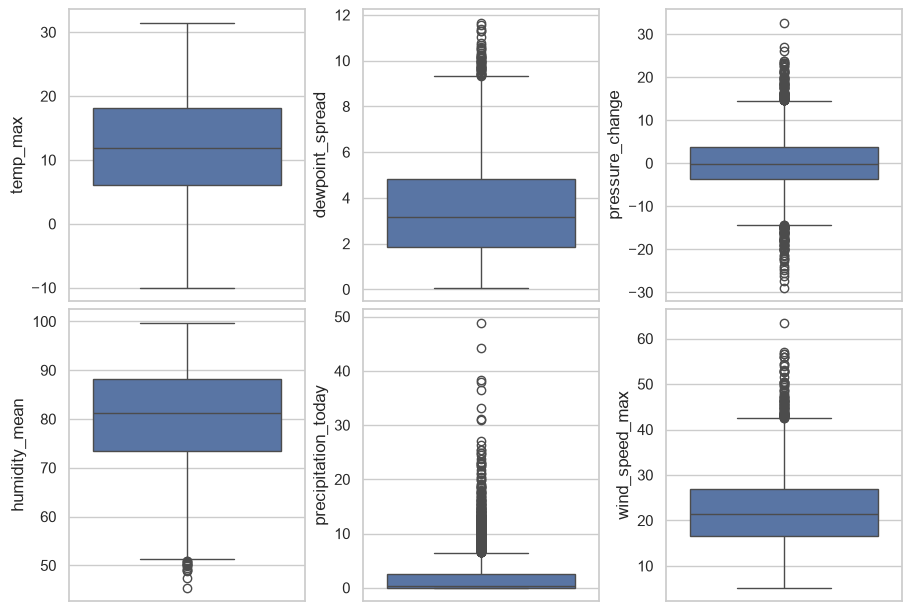

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(9, 6), constrained_layout=True)
axes = axes.flatten()
for i, col in enumerate(features_to_check):
    sns.boxplot(data=df_daily, y=col, ax=axes[i])

plt.show()

## 2. Unsupervised Learing - K-means Clustering

In [21]:
# 1. Select features for clustering
cluster_features = [
    "temp_mean",
    "temp_range",
    "humidity_mean",
    "dewpoint_spread",
    "pressure_mean",
    "pressure_change",
    "cloud_cover_mean",
    "wind_speed_max"
]


In [22]:
#  Supervised Learning - Dataset Splitting

In [23]:
# 1. Copy the existing dataset and ensure chronological order
df_model = df_daily.copy()

df_model["date"] = pd.to_datetime(df_model["date"])
df_model = (
    df_model.sort_values("date")
    .reset_index(drop=True)
)

# 2. Select today's weather features
feature_cols = [
    "temp_max",
    "temp_min",
    "temp_mean",
    "humidity_mean",
    "dewpoint_mean",
    "pressure_mean",
    "cloud_cover_mean",
    "wind_speed_max",
    "precipitation_today",
    "temp_range",
    "dewpoint_spread",
    "pressure_change",
    "month_cos",
    "month_sin"
]

X = df_model[feature_cols]
y = df_model["rain_tomorrow"].astype(int)

# 3. Split: 70% / 15% / 15%
n = len(df_model)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

# 4. Print date ranges and dataset sizes
print("=== Dataset Split ===")

for name, start, end, X_part, y_part in [
    ("Training", 0, train_end, X_train, y_train),
    ("Validation", train_end, val_end, X_val, y_val),
    ("Test", val_end, n, X_test, y_test)
]:
    print(f"\n{name} Set")
    print("Number of samples:", len(X_part))
    print(
        "Date range:",
        df_model["date"].iloc[start].date(),
        "to",
        df_model["date"].iloc[end - 1].date()
    )
    print("RainTomorrow proportions:")
    print(y_part.value_counts(normalize=True).sort_index().round(3))

=== Dataset Split ===

Training Set
Number of samples: 3834
Date range: 2010-01-01 to 2020-06-30
RainTomorrow proportions:
rain_tomorrow
0    0.456
1    0.544
Name: proportion, dtype: float64

Validation Set
Number of samples: 822
Date range: 2020-07-01 to 2022-09-30
RainTomorrow proportions:
rain_tomorrow
0    0.426
1    0.574
Name: proportion, dtype: float64

Test Set
Number of samples: 822
Date range: 2022-10-01 to 2024-12-30
RainTomorrow proportions:
rain_tomorrow
0    0.4
1    0.6
Name: proportion, dtype: float64


In [24]:
# Weather Clustering fitted on Training Set

In [25]:
X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

# 1. Select clustering features in chronological order
X_cluster = df_model[cluster_features]

# 2. Split clustering data using the same boundaries
X_cluster_train = X_cluster.iloc[:train_end]
X_cluster_val = X_cluster.iloc[train_end:val_end]
X_cluster_test = X_cluster.iloc[val_end:]

# 3. Fit the scaler using training data only
scaler_cluster = StandardScaler()

X_cluster_train_scaled = scaler_cluster.fit_transform(
    X_cluster_train
)

X_cluster_val_scaled = scaler_cluster.transform(
    X_cluster_val
)

X_cluster_test_scaled = scaler_cluster.transform(
    X_cluster_test
)

# 4. Fit K-Means using training data only
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

train_clusters = kmeans.fit_predict(
    X_cluster_train_scaled
)

# 5. Assign clusters to validation and test data
val_clusters = kmeans.predict(
    X_cluster_val_scaled
)

test_clusters = kmeans.predict(
    X_cluster_test_scaled
)

# 6. Add weather_cluster as a new feature
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

X_train["weather_cluster"] = train_clusters
X_val["weather_cluster"] = val_clusters
X_test["weather_cluster"] = test_clusters

d:\Dev\Python\conda\miniforge3\envs\bern02_tf\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=15.
  warnings.warn(


In [26]:
# PCA Visualization of Training Weather Clusters

Explained variance ratio: [0.4097 0.1962]
Total variance explained: 0.6059


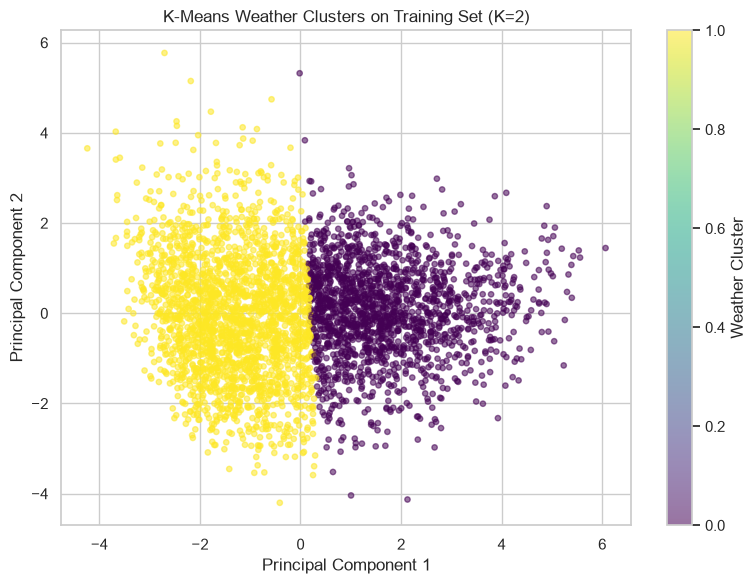

=== Weather Cluster Feature ===

Training cluster counts:
weather_cluster
0    1655
1    2179
Name: count, dtype: int64

Validation cluster counts:
weather_cluster
0    418
1    404
Name: count, dtype: int64

Test cluster counts:
weather_cluster
0    350
1    472
Name: count, dtype: int64

Updated feature count: 15
Training shape: (3834, 15)
Validation shape: (822, 15)
Test shape: (822, 15)


In [27]:
# Fit PCA on the standardized training data only
pca = PCA(n_components=2, random_state=42)

X_train_pca = pca.fit_transform(
    X_cluster_train_scaled
)

print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_.round(4)
)
print(
    "Total variance explained:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

# Plot training samples, colored by their K-Means cluster
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=train_clusters,
    cmap="viridis",
    alpha=0.55,
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Weather Clusters on Training Set (K=2)")
plt.colorbar(label="Weather Cluster")
plt.tight_layout()
plt.show()



#  Check the results
print("=== Weather Cluster Feature ===")

print("\nTraining cluster counts:")
print(X_train["weather_cluster"].value_counts().sort_index())

print("\nValidation cluster counts:")
print(X_val["weather_cluster"].value_counts().sort_index())

print("\nTest cluster counts:")
print(X_test["weather_cluster"].value_counts().sort_index())

print("\nUpdated feature count:", X_train.shape[1])
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

In [28]:
#=============================================
#Training effect explore
#=============================================

In [29]:
# 1. Majority-class baseline
baseline_class = y_train.mode().iloc[0]

baseline_pred = np.full(
    len(y_val),
    baseline_class
)

print("=== Majority-Class Baseline ===")
print("Predicted class:", baseline_class)
print("Validation Accuracy:",
      round(accuracy_score(y_val, baseline_pred), 4))

=== Majority-Class Baseline ===
Predicted class: 1
Validation Accuracy: 0.5742


In [30]:
# Persistence Baseline
baseline_pred_persistence = (
    df_model["precipitation_today"].iloc[train_end:val_end] > 0.1
).astype(int)

# Evaluate on the validation set
print("=== Persistence Baseline ===")
print(
    "Validation Accuracy:",
    round(accuracy_score(y_val, baseline_pred_persistence), 4)
)
print(
    "Validation F1-score:",
    round(f1_score(y_val, baseline_pred_persistence), 4)
)


=== Persistence Baseline ===
Validation Accuracy: 0.6898
Validation F1-score: 0.7296


## 3. Supervised Learning - Random Forest Classification

In [31]:
#========================
# Initial model training
#======================

In [32]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Fit the model using the training set only
rf.fit(X_train, y_train)

# Predictions on the validation set
y_val_pred = rf.predict(X_val)
y_val_prob = rf.predict_proba(X_val)[:, 1]

# Validation Evaluation
print("\n=== Random Forest Validation Results ===")

print("Accuracy:",
      round(accuracy_score(y_val, y_val_pred), 4))

print("Precision:",
      round(precision_score(
          y_val, y_val_pred, zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_val, y_val_pred, zero_division=0
      ), 4))

print("F1-score:",
      round(f1_score(
          y_val, y_val_pred, zero_division=0
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_val, y_val_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["No Rain", "Rain Tomorrow"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))


=== Random Forest Validation Results ===
Accuracy: 0.7141
Precision: 0.7365
Recall: 0.7818
F1-score: 0.7585
ROC-AUC: 0.7659

Classification Report:
               precision    recall  f1-score   support

      No Rain       0.68      0.62      0.65       350
Rain Tomorrow       0.74      0.78      0.76       472

     accuracy                           0.71       822
    macro avg       0.71      0.70      0.70       822
 weighted avg       0.71      0.71      0.71       822

Confusion Matrix:
[[218 132]
 [103 369]]


In [33]:
# Feature Importance - Random Forest Built-in Method

=== Random Forest Feature Importance ===
            feature  importance
      pressure_mean      0.1401
precipitation_today      0.1187
   cloud_cover_mean      0.0934
    pressure_change      0.0817
     wind_speed_max      0.0743
      humidity_mean      0.0664
    dewpoint_spread      0.0648
      dewpoint_mean      0.0640
         temp_range      0.0639
          temp_mean      0.0621
           temp_min      0.0597
           temp_max      0.0586
          month_sin      0.0243
          month_cos      0.0222
    weather_cluster      0.0061


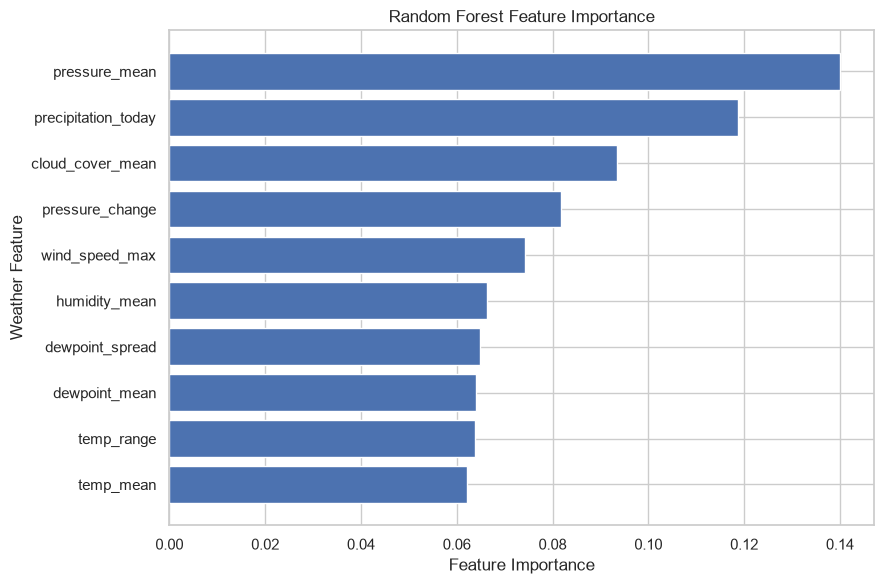

In [34]:
# Extract feature importance from the trained Random Forest
importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf.feature_importances_
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="importance",
    ascending=False
)

print("=== Random Forest Feature Importance ===")
print(importance_df.round(4).to_string(index=False))

# Plot the top 10 features
top10 = importance_df.head(10).sort_values(
    by="importance",
    ascending=True
)

plt.figure(figsize=(9, 6))
plt.barh(
    top10["feature"],
    top10["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Weather Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [35]:
# ROC Curve - Random Forest Validation

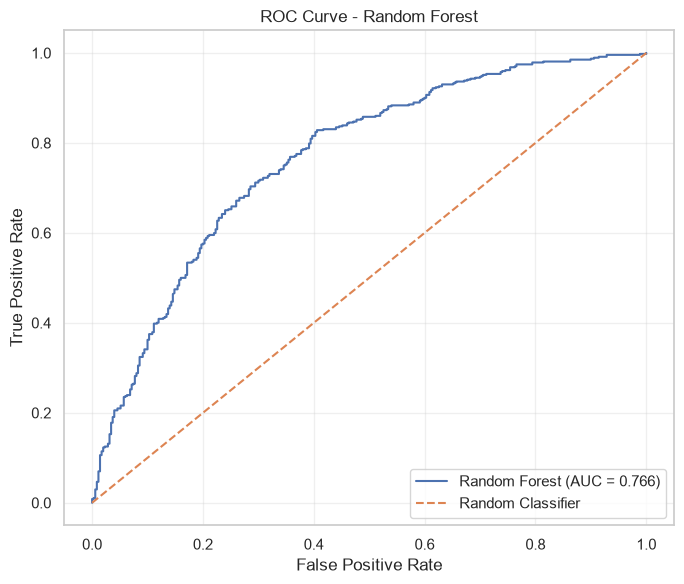

Validation ROC-AUC: 0.7659


In [36]:
# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_val, y_val_prob)

# Calculate AUC
roc_auc = roc_auc_score(y_val, y_val_prob)

# Plot
plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.3f})"
)

# Reference line for random guessing
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Validation ROC-AUC: {roc_auc:.4f}")

In [37]:
#==========================================================
# Random Forest Hyperparameter Comparison-can we improve it?
#===========================================================

In [38]:
if 0:
    param_grid = {
        'n_estimators': [100,200,300],
        'max_depth': [1, 2, 3, 4],
        'min_samples_leaf': [10, 20, 50, 100, 200]
    }

    grid_search = GridSearchCV(
        estimator=RandomForestClassifier(random_state=42,class_weight='balanced'),
        param_grid=param_grid,
        cv=TimeSeriesSplit(n_splits=3), 
        scoring='f1',
        n_jobs=-1,
        verbose=1
    )


    print("Conducting grid search...")
    grid_search.fit(X_train, y_train)


    print(f"Best hyperparameters: {grid_search.best_params_}")
    print(f"Highest F1 score in test set: {grid_search.best_score_:.4f}")


    final_rf = grid_search.best_estimator_

hypeparameter chosen:

n_estimators=300
max_depth=1
min_samples_leaf=50

In [39]:
# Final Model: Train on Training + Validation Sets

In [40]:
# 1. Combine training and validation sets
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

# 2. Train the final Random Forest
final_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=1,
    min_samples_leaf=50,
    random_state=42,
    n_jobs=-1
)

final_rf.fit(X_train_val, y_train_val)

# 3. Predict on the untouched test set
y_test_pred = final_rf.predict(X_test)
y_test_prob = final_rf.predict_proba(X_test)[:, 1]

# 4. Evaluate final model
print("=== Final Random Forest: Test Results ===")

print("Accuracy:",
      round(accuracy_score(y_test, y_test_pred), 4))

print("Precision:",
      round(precision_score(
          y_test, y_test_pred, zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_test, y_test_pred, zero_division=0
      ), 4))

print("F1-score:",
      round(f1_score(
          y_test, y_test_pred, zero_division=0
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_test_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["No Rain", "Rain Tomorrow"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred, labels=[0, 1]))



=== Final Random Forest: Test Results ===
Accuracy: 0.7263
Precision: 0.7271
Recall: 0.8702
F1-score: 0.7922
ROC-AUC: 0.7805

Classification Report:
               precision    recall  f1-score   support

      No Rain       0.72      0.51      0.60       329
Rain Tomorrow       0.73      0.87      0.79       493

     accuracy                           0.73       822
    macro avg       0.73      0.69      0.70       822
 weighted avg       0.73      0.73      0.71       822

Confusion Matrix:
[[168 161]
 [ 64 429]]


In [ ]:
# Output model

joblib.dump(final_rf, "./models/final_rf.joblib")
joblib.dump(scaler_cluster, "./models/scaler_cluster.joblib")
joblib.dump(kmeans, "./models/kmeans_weather.joblib")
print("Model saved successfully.")

Model saved successfully.


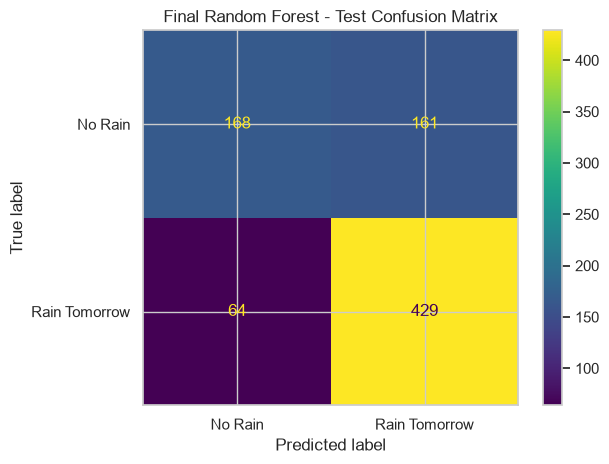

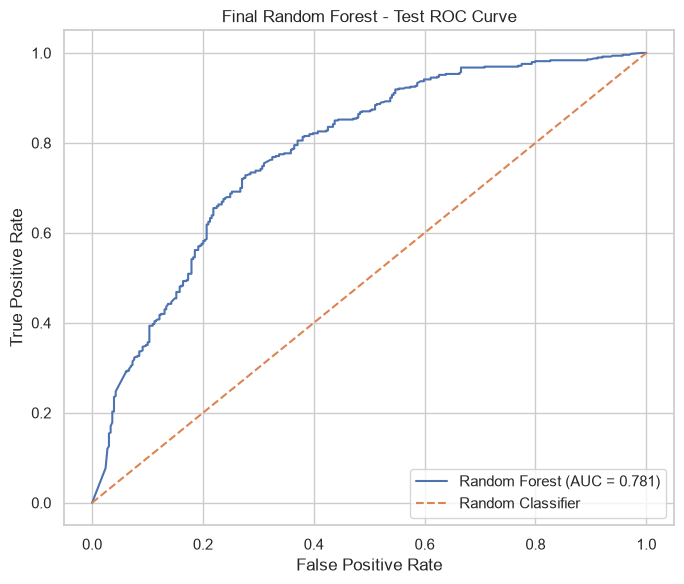

=== Final Model Feature Importance ===
            feature  importance
precipitation_today      0.2267
      pressure_mean      0.1633
   cloud_cover_mean      0.1267
     wind_speed_max      0.0967
    weather_cluster      0.0833
    pressure_change      0.0767
         temp_range      0.0667
      humidity_mean      0.0633
    dewpoint_spread      0.0467
      dewpoint_mean      0.0200
           temp_min      0.0200
          temp_mean      0.0100
           temp_max      0.0000
          month_cos      0.0000
          month_sin      0.0000


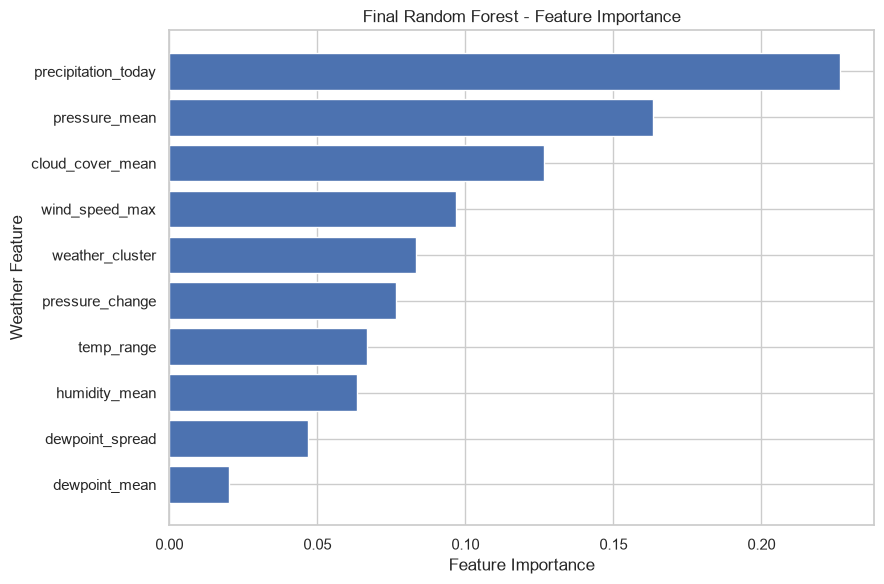


Final Test ROC-AUC: 0.7805


In [ ]:
# ==============================================================================
# Final Model Visualization
# ==============================================================================

# 1. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=[0, 1],
    display_labels=["No Rain", "Rain Tomorrow"],
    values_format="d"
)

plt.title("Final Random Forest - Test Confusion Matrix")
plt.tight_layout()
plt.savefig("./outputs/test_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


# 2. ROC Curve on the Test Set
fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)
test_auc = roc_auc_score(y_test, y_test_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {test_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Random Forest - Test ROC Curve")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("./outputs/test_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()


# 3. Feature Importance of the Final Model
importance_df = pd.DataFrame({
    "feature": X_train_val.columns,
    "importance": final_rf.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

print("=== Final Model Feature Importance ===")
print(importance_df.round(4).to_string(index=False))

top10 = importance_df.head(10).sort_values("importance")

plt.figure(figsize=(9, 6))
plt.barh(top10["feature"], top10["importance"])

plt.xlabel("Feature Importance")
plt.ylabel("Weather Feature")
plt.title("Final Random Forest - Feature Importance")
plt.tight_layout()
plt.savefig("./outputs/test_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"\nFinal Test ROC-AUC: {test_auc:.4f}")

## 4. Neural Network Implementation

> The aim of this part is to develop a feedforward neural network to predict the next-day rainfall in Lund and compare it performance with the Random Forest classifier.

In [15]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import StandardScaler

### 4.1. Data Preperation

In [ ]:
tf.keras.utils.set_random_seed(7)
scaler_nn = StandardScaler()

nn_features = [
    col for col in X_train.columns
    if col != "weather_cluster"  # binary feature
]

X_train_nn = scaler_nn.fit_transform(X_train[nn_features])
X_val_nn = scaler_nn.transform(X_val[nn_features])
X_test_nn = scaler_nn.transform(X_test[nn_features])

X_train_nn = np.column_stack([X_train_nn, X_train["weather_cluster"].to_numpy()])
X_val_nn = np.column_stack([X_val_nn, X_val["weather_cluster"].to_numpy()])
X_test_nn = np.column_stack([X_test_nn, X_test["weather_cluster"].to_numpy()])

print("Training:", X_train_nn.shape)
print("Validation:", X_val_nn.shape)
print("Test:", X_test_nn.shape)

Training: (3834, 15)
Validation: (822, 15)
Test: (822, 15)


### 4.2. Model Building

1. Input Layer (15 features)
2. Dense Layer - 64 neurons (ReLU activation), Dropout (0.2)
3. Dense Layer - 32 neurons (ReLU activation), Dropout (0.2)
4. Output Layer (Sigmoid activation)

In [17]:
num_features = X_train_nn.shape[1]

model = Sequential([
    Input(shape=(num_features,)),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(32, activation="relu"),
    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,137 (12.25 KB)

 Trainable params: 3,137 (12.25 KB)

 Non-trainable params: 0 (0.00 B)

### 4.3. Model Training

In [18]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_nn,
    y_train,

    validation_data=(X_val_nn, y_val),

    epochs=100,
    batch_size=32,

    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6484 - loss: 0.6396 - val_accuracy: 0.7336 - val_loss: 0.5686
Epoch 2/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6690 - loss: 0.6146 - val_accuracy: 0.7165 - val_loss: 0.5687
Epoch 3/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6797 - loss: 0.6023 - val_accuracy: 0.7190 - val_loss: 0.5640
Epoch 4/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6787 - loss: 0.6005 - val_accuracy: 0.7178 - val_loss: 0.5641
Epoch 5/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6888 - loss: 0.5958 - val_accuracy: 0.7202 - val_loss: 0.5652
Epoch 6/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6881 - loss: 0.5933 - val_accuracy: 0.7129 - val_loss: 0.5632
Epoch 7/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6896 - loss: 0.5972 - val_accuracy: 0.7190 - val_loss: 0.5628
Epoch 8/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6907 - loss: 0.5919 - val_accu

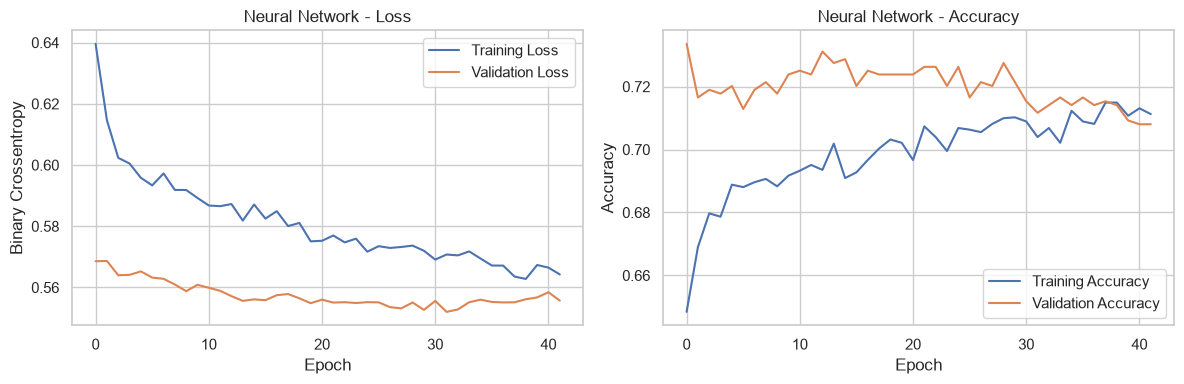

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(history.history["loss"], label="Training Loss")
axes[0].plot(history.history["val_loss"], label="Validation Loss")

axes[0].set_title("Neural Network - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Crossentropy")
axes[0].legend()

# Accuracy
axes[1].plot(history.history["accuracy"], label="Training Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation Accuracy")

axes[1].set_title("Neural Network - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

### 4.4. Model Evaluation

In [43]:
def model_evaluation(y, y_prob, y_pred):
    accuracy_nn = accuracy_score(y, y_pred)
    precision_nn = precision_score(y, y_pred, zero_division=0)
    recall_nn = recall_score(y, y_pred, zero_division=0)
    f1_nn = f1_score(y, y_pred, zero_division=0)
    roc_auc_nn = roc_auc_score(y, y_prob)

    print(f"Accuracy: {accuracy_nn:.4f}")
    print(f"Precision: {precision_nn:.4f}")
    print(f"Recall: {recall_nn:.4f}")
    print(f"F1-score: {f1_nn:.4f}")
    print(f"ROC-AUC: {roc_auc_nn:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y,
        y_pred,
        target_names=["No Rain", "Rain Tomorrow"],
        zero_division=0
    ))

In [45]:
y_val_prob_nn = model.predict(X_val_nn).ravel()
y_val_pred_nn = (y_val_prob_nn >= 0.5).astype(int)

print("=== Neural Network Validation Results ===")
model_evaluation(y_val, y_val_prob_nn, y_val_pred_nn)

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
=== Neural Network Validation Results ===
Accuracy: 0.7117
Precision: 0.7453
Recall: 0.7564
F1-score: 0.7508
ROC-AUC: 0.7887

Classification Report:
               precision    recall  f1-score   support

      No Rain       0.66      0.65      0.66       350
Rain Tomorrow       0.75      0.76      0.75       472

     accuracy                           0.71       822
    macro avg       0.71      0.70      0.70       822
 weighted avg       0.71      0.71      0.71       822



In [46]:
y_test_prob_nn = model.predict(X_test_nn).ravel()
y_test_pred_nn = (y_test_prob_nn >= 0.5).astype(int)

print("=== Neural Network Test Results ===")
model_evaluation(y_test, y_test_prob_nn, y_test_pred_nn)

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
=== Neural Network Test Results ===
Accuracy: 0.7372
Precision: 0.7689
Recall: 0.8032
F1-score: 0.7857
ROC-AUC: 0.7712

Classification Report:
               precision    recall  f1-score   support

      No Rain       0.68      0.64      0.66       329
Rain Tomorrow       0.77      0.80      0.79       493

     accuracy                           0.74       822
    macro avg       0.73      0.72      0.72       822
 weighted avg       0.73      0.74      0.74       822



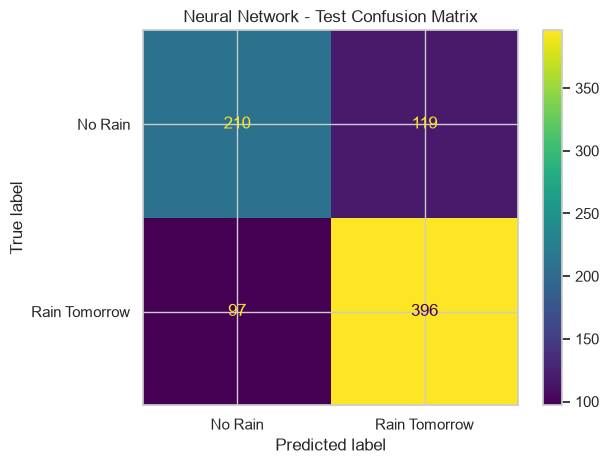

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_nn,
    labels=[0, 1],
    display_labels=["No Rain", "Rain Tomorrow"],
    values_format="d"
)

plt.title("Neural Network - Test Confusion Matrix")
plt.tight_layout()
# plt.savefig("./outputs/test_confusion_matrix_nn.png", dpi=300, bbox_inches="tight")
plt.show()